Studi Kasus: Apa yang Dibahas Portal Berita pada Paruh Pertama 2020?

In [3]:
import os, re, collections, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

Langkah 1 – Unduh data

Mengunduh CSV judul berita detik.com. Jika gagal, unggah berkas detik_news_title.csv ke panel file Colab, lalu jalankan ulang sel ini.

In [4]:
URL_DATA = ("https://raw.githubusercontent.com/ibamibrahim/"
            "dataset-judul-berita-indonesia/master/detik_news_title.csv")
NAMA_FILE = "detik_news_title.csv"

if not os.path.exists(NAMA_FILE):
    urllib.request.urlretrieve(URL_DATA, NAMA_FILE)

mentah = pd.read_csv(NAMA_FILE)
print("Baris, kolom:", mentah.shape)   # diharapkan (91017, 4)

Baris, kolom: (91017, 4)


Langkah 2 – Bersihkan data (sama dengan H-6)

Merapikan spasi, membuang judul duplikat, menyaring judul 3–30 kata, mengubah tanggal ke datetime, dan membuat kolom bulan.

In [5]:
bersih = mentah.rename(columns={"date": "tanggal", "title": "judul",
                                "category": "kategori"}).copy()
bersih["judul"] = (bersih["judul"].fillna("")
                   .str.replace(r"\s+", " ", regex=True).str.strip())
bersih = bersih.drop_duplicates(subset="judul", keep="first")
bersih = bersih[bersih["judul"].str.split().str.len().between(3, 30)].copy()
bersih["tanggal"] = pd.to_datetime(bersih["tanggal"], format="%m/%d/%Y")
bersih["bulan"] = bersih["tanggal"].dt.strftime("%Y-%m")

print("Baris setelah dibersihkan:", f"{len(bersih):,}")   # diharapkan 90,818

Baris setelah dibersihkan: 90,818


Langkah 3 – (a) Kapan topik corona memuncak?

Menghitung judul yang memuat kata “corona” per bulan, lengkap dengan persentase dan rata-rata per hari agar Juni (13 hari) bisa dibandingkan secara adil.

In [6]:
bersih["ada_corona"] = bersih["judul"].str.lower().str.contains("corona", regex=False)

tabel_bulan = bersih.groupby("bulan").agg(
    total_judul=("judul", "size"),
    judul_corona=("ada_corona", "sum"),
    hari_data=("tanggal", "nunique"),
)
tabel_bulan["persen_corona"] = (tabel_bulan["judul_corona"] / tabel_bulan["total_judul"] * 100).round(1)
tabel_bulan["corona_per_hari"] = (tabel_bulan["judul_corona"] / tabel_bulan["hari_data"]).round(1)
print(tabel_bulan)
# judul_corona diharapkan: 385, 1077, 6994, 4913, 2934, 943

         total_judul  judul_corona  hari_data  persen_corona  corona_per_hari
bulan                                                                        
2020-01        16258           385         31            2.4             12.4
2020-02        16135          1077         29            6.7             37.1
2020-03        18103          6994         31           38.6            225.6
2020-04        16636          4913         30           29.5            163.8
2020-05        16352          2934         31           17.9             94.6
2020-06         7334           943         13           12.9             72.5


Grafik batang untuk memperlihatkan puncaknya.

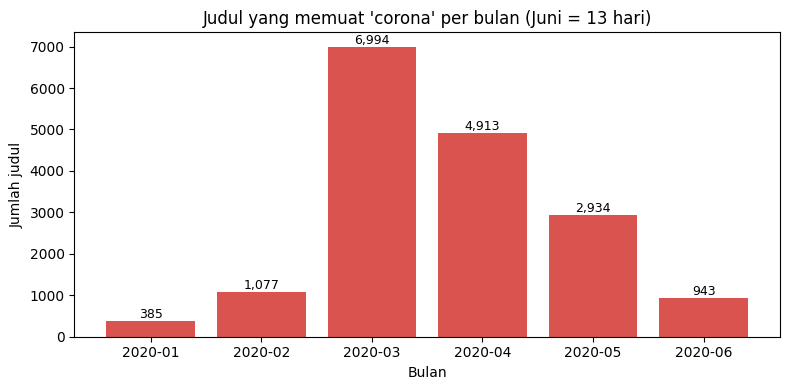

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tabel_bulan.index, tabel_bulan["judul_corona"], color="#d9534f")
for i, v in enumerate(tabel_bulan["judul_corona"]):
    ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Judul yang memuat 'corona' per bulan (Juni = 13 hari)")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah judul")
plt.tight_layout()
plt.show()

Langkah 4 – (b) Kategori mana yang paling banyak membahas corona?

Menghitung jumlah dan persentase judul corona di setiap kategori.

In [8]:
tabel_kat = bersih.groupby("kategori").agg(
    total_judul=("judul", "size"),
    judul_corona=("ada_corona", "sum"),
)
tabel_kat["persen_corona"] = (tabel_kat["judul_corona"] / tabel_kat["total_judul"] * 100).round(1)
print(tabel_kat.sort_values("judul_corona", ascending=False))

          total_judul  judul_corona  persen_corona
kategori                                          
news            32321          7532           23.3
health           4914          2591           52.7
finance         14141          2473           17.5
hot             16290          1663           10.2
travel           6453          1025           15.9
inet             5577           847           15.2
oto              4375           577           13.2
food             4314           310            7.2
sport            2433           228            9.4


Langkah 5 – Kata teratas per kategori dan kategori yang paling berbeda

Menghitung lima kata teratas tiap kategori (tanpa stopword), lalu mengukur seberapa banyak 20 kata teratas suatu kategori sama dengan 20 kata teratas keseluruhan. Skor terendah berarti bahasannya paling berbeda.

In [9]:
STOPWORD = set("""yang di dan ke dari ini itu untuk dengan pada adalah akan tak tidak jadi soal
saat ada bisa juga oleh atau karena sebagai dalam usai hingga jika saja para lebih hanya
sudah belum masih kini lagi pun serta agar bakal dua tiga kok nih ya yg dgn""".split())

kata_kat = {}
for kat, g in bersih.groupby("kategori"):
    c = collections.Counter()
    for t in g["judul"]:
        c.update(k for k in re.findall(r"[a-z]+", t.lower()) if k not in STOPWORD)
    kata_kat[kat] = c

print("5 kata teratas per kategori:")
for kat in sorted(kata_kat):
    print(f"  {kat:<8}", ", ".join(f"{k} ({n:,})" for k, n in kata_kat[kat].most_common(5)))

total_kata = sum(kata_kat.values(), collections.Counter())
top_semua = {k for k, _ in total_kata.most_common(20)}

kemiripan = {kat: len({k for k, _ in c.most_common(20)} & top_semua) / 20
             for kat, c in kata_kat.items()}
print("\nKemiripan 20 kata teratas dengan keseluruhan (rendah = paling berbeda):")
for kat, s in sorted(kemiripan.items(), key=lambda x: x[1]):
    print(f"  {kat:<8} {s:.2f}")

5 kata teratas per kategori:
  finance  corona (2,470), rp (1,385), ri (1,125), harga (701), jokowi (642)
  food     makanan (699), makan (539), foto (458), galeri (438), enak (358)
  health   corona (2,590), virus (1,040), pasien (471), indonesia (427), meninggal (413)
  hot      corona (1,658), anak (793), rumah (561), meninggal (545), the (528)
  inet     corona (845), virus (341), ponsel (309), bikin (253), indonesia (249)
  news     corona (7,539), polisi (2,244), kasus (2,015), warga (1,972), positif (1,876)
  oto      mobil (1,205), corona (576), motor (432), rp (267), indonesia (256)
  sport    corona (228), indonesia (223), motogp (209), masters (127), olimpiade (124)
  travel   corona (1,023), wisata (525), foto (333), dunia (299), turis (284)

Kemiripan 20 kata teratas dengan keseluruhan (rendah = paling berbeda):
  sport    0.15
  food     0.20
  travel   0.20
  finance  0.25
  inet     0.35
  hot      0.40
  health   0.45
  oto      0.50
  news     0.60


Langkah 6 – (c) Keterbatasan data

Memeriksa rentang tanggal, jumlah hari tiap bulan, dan jumlah URL rusak untuk dijadikan bahan keterbatasan.

In [10]:
print("Rentang tanggal:", bersih["tanggal"].min().date(), "s.d.", bersih["tanggal"].max().date())
print("Hari data per bulan:", bersih.groupby("bulan")["tanggal"].nunique().to_dict())

url_rusak = (~mentah["url"].astype(str).str.contains(r"/d-?\d+", regex=True)).sum()
print("Baris dengan url rusak:", f"{url_rusak:,}")   # diharapkan 5,640 (seluruh kategori inet)
print("Kolom yang tersedia  :", list(mentah.columns), "-> hanya judul, tanpa isi artikel")

Rentang tanggal: 2020-01-01 s.d. 2020-06-13
Hari data per bulan: {'2020-01': 31, '2020-02': 29, '2020-03': 31, '2020-04': 30, '2020-05': 31, '2020-06': 13}
Baris dengan url rusak: 5,640
Kolom yang tersedia  : ['date', 'url', 'title', 'category'] -> hanya judul, tanpa isi artikel


Langkah 7 – Ringkasan untuk pimpinan redaksi (150–200 kata)

Draf ringkasan di bawah memakai angka dari modul. Cocokkan dengan output sel-sel di atas, lalu ubah kalimatnya dengan gayamu sendiri. Sel ini juga menghitung jumlah katanya.

In [11]:
ringkasan = """Topik corona mendominasi pemberitaan pada paruh pertama 2020. Jumlah judul yang memuat kata corona naik dari 385 pada Januari menjadi 1.077 pada Februari, memuncak pada Maret dengan 6.994 judul, lalu turun menjadi 4.913 pada April dan 2.934 pada Mei. Juni baru mencakup 13 hari tetapi sudah mencatat 943 judul, sekitar 73 judul per hari, sehingga penurunannya tidak setajam yang tampak pada angka mentah. Kategori news paling banyak membahas corona (7.539 kemunculan kata), disusul health (2.590) dan finance (2.470). Pandemi juga merembes ke kategori nonkesehatan seperti finance, travel, dan inet. Corona menjadi kata teratas di tujuh dari sembilan kategori. Kategori yang bahasannya paling berbeda adalah food, yang didominasi kata makanan, makan, dan enak, serta oto yang didominasi mobil dan motor. Keterbatasan data: hanya berisi judul, bukan isi artikel, sehingga kedalaman pembahasan tidak dapat diukur; periode Juni tidak penuh; dan seluruh url kategori inet rusak sehingga judulnya tidak dapat ditelusuri ke artikel asli."""

print(ringkasan)
print("\nJumlah kata:", len(ringkasan.split()))

Topik corona mendominasi pemberitaan pada paruh pertama 2020. Jumlah judul yang memuat kata corona naik dari 385 pada Januari menjadi 1.077 pada Februari, memuncak pada Maret dengan 6.994 judul, lalu turun menjadi 4.913 pada April dan 2.934 pada Mei. Juni baru mencakup 13 hari tetapi sudah mencatat 943 judul, sekitar 73 judul per hari, sehingga penurunannya tidak setajam yang tampak pada angka mentah. Kategori news paling banyak membahas corona (7.539 kemunculan kata), disusul health (2.590) dan finance (2.470). Pandemi juga merembes ke kategori nonkesehatan seperti finance, travel, dan inet. Corona menjadi kata teratas di tujuh dari sembilan kategori. Kategori yang bahasannya paling berbeda adalah food, yang didominasi kata makanan, makan, dan enak, serta oto yang didominasi mobil dan motor. Keterbatasan data: hanya berisi judul, bukan isi artikel, sehingga kedalaman pembahasan tidak dapat diukur; periode Juni tidak penuh; dan seluruh url kategori inet rusak sehingga judulnya tidak da

Latihan

Memasang pustaka yang dibutuhkan.

In [12]:
!pip install -q duckdb beautifulsoup4 lxml requests pyarrow pandas

Mengimpor pustaka dan mengunduh CSV judul berita. Jika unduhan gagal, unggah detik_news_title.csv ke panel file Colab.

In [13]:
import os, re, json, time, zlib, queue, threading, collections, shutil, urllib.request
from pathlib import Path
import pandas as pd

URL_DATA = ("https://raw.githubusercontent.com/ibamibrahim/"
            "dataset-judul-berita-indonesia/master/detik_news_title.csv")
if not os.path.exists("detik_news_title.csv"):
    urllib.request.urlretrieve(URL_DATA, "detik_news_title.csv")

df_sumber = pd.read_csv("detik_news_title.csv")
print("Baris, kolom:", df_sumber.shape)   # diharapkan (91017, 4)

Baris, kolom: (91017, 4)


Membersihkan data seperti H-6: rapikan spasi, buang duplikat, saring judul 3–30 kata, buat kolom bulan dan id.

In [14]:
mentah = df_sumber.rename(columns={"date": "tanggal", "title": "judul", "category": "kategori"}).copy()
mentah["tanggal"] = pd.to_datetime(mentah["tanggal"], format="%m/%d/%Y").dt.strftime("%Y-%m-%d")

bersih = mentah.copy()
bersih["judul"] = bersih["judul"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
bersih = bersih.drop_duplicates(subset="judul", keep="first")
bersih = bersih[bersih["judul"].str.split().str.len().between(3, 30)].copy()
bersih["tanggal"] = pd.to_datetime(bersih["tanggal"], format="%Y-%m-%d")
bersih["bulan"] = bersih["tanggal"].dt.strftime("%Y-%m")
bersih["id"] = pd.to_numeric(bersih["url"].str.extract(r"/d-?(\d+)")[0], errors="coerce").astype("Int64")
bersih["url"] = bersih["url"].where(bersih["url"].str.contains(r"/d-?\d+", regex=True))

print("Baris setelah dibersihkan:", f"{len(bersih):,}")   # diharapkan 90,818

Baris setelah dibersihkan: 90,818


Menyimpan Parquet berpartisi per kategori, lalu menyiapkan stopword, tokenisasi, dan mapper dasar dari H-9.

In [15]:
TERKURASI = "lapisan_terkurasi"
shutil.rmtree(TERKURASI, ignore_errors=True)
bersih.to_parquet(TERKURASI, partition_cols=["kategori"], index=False)

STOPWORD = set("""yang di dan ke dari ini itu untuk dengan pada adalah akan tak tidak jadi soal
saat ada bisa juga oleh atau karena sebagai dalam usai hingga jika saja para lebih hanya
sudah belum masih kini lagi pun serta agar bakal dua tiga kok nih ya yg dgn""".split())

def tokenisasi(teks):
    return re.findall(r"[a-z]+", teks.lower())

splits = sorted(Path(TERKURASI).rglob("*.parquet"))

def mapper_split(path):
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    return [(kata, 1) for t in judul for kata in tokenisasi(t)]

print("Jumlah input split:", len(splits))   # diharapkan 9
total_pasangan = sum(len(mapper_split(p)) for p in splits)
print("Pasangan dari semua mapper:", f"{total_pasangan:,}")   # diharapkan 825,601

Jumlah input split: 9
Pasangan dari semua mapper: 825,601


LATIHAN 1 – Stopword domain

Menambahkan 5 kata pengganggu (rp, ri, the, foto, galeri) ke stopword, lalu membandingkan lima kata teratas tiap kategori sebelum dan sesudah.

In [16]:
def hitung_kategori(stop):
    gabung = collections.Counter()
    for p in splits:
        kategori = p.parent.name.split("=")[1]
        judul = pd.read_parquet(p, columns=["judul"])["judul"]
        for t in judul:
            for kata in tokenisasi(t):
                if kata not in stop:
                    gabung[(kategori, kata)] += 1
    return gabung

def top5(gabung):
    per = collections.defaultdict(list)
    for (kat, kata), n in gabung.items():
        per[kat].append((n, kata))
    return {kat: sorted(v, reverse=True)[:5] for kat, v in per.items()}

KATA_BARU = ["rp", "ri", "the", "foto", "galeri"]
STOPWORD_BARU = STOPWORD | set(KATA_BARU)

sebelum = top5(hitung_kategori(STOPWORD))
sesudah = top5(hitung_kategori(STOPWORD_BARU))

print("Kata ditambahkan ke STOPWORD:", KATA_BARU, "\n")
for kat in sorted(sebelum):
    lama = [k for _, k in sebelum[kat]]
    baru = [k for _, k in sesudah[kat]]
    masuk = [k for k in baru if k not in lama]
    print(f"{kat:<8} sebelum: {', '.join(lama)}")
    print(f"{'':<8} sesudah: {', '.join(baru)}   | kata baru masuk: {masuk if masuk else '-'}")

Kata ditambahkan ke STOPWORD: ['rp', 'ri', 'the', 'foto', 'galeri'] 

finance  sebelum: corona, rp, ri, harga, jokowi
         sesudah: corona, harga, jokowi, mau, ekonomi   | kata baru masuk: ['mau', 'ekonomi']
food     sebelum: makanan, makan, foto, galeri, enak
         sesudah: makanan, makan, enak, bikin, rumah   | kata baru masuk: ['bikin', 'rumah']
health   sebelum: corona, virus, pasien, indonesia, meninggal
         sesudah: corona, virus, pasien, indonesia, meninggal   | kata baru masuk: -
hot      sebelum: corona, anak, rumah, meninggal, the
         sesudah: corona, anak, rumah, meninggal, film   | kata baru masuk: ['film']
inet     sebelum: corona, virus, ponsel, bikin, indonesia
         sesudah: corona, virus, ponsel, bikin, indonesia   | kata baru masuk: -
news     sebelum: corona, polisi, kasus, warga, positif
         sesudah: corona, polisi, kasus, warga, positif   | kata baru masuk: -
oto      sebelum: mobil, corona, motor, rp, indonesia
         sesudah: mobil, cor

LATIHAN 2 – Key (bulan, kata)

Mengubah key menjadi (bulan, kata) dan membandingkan 10 kata teratas Januari dengan Mei.

In [17]:
gabung_bulan = collections.Counter()
for p in splits:
    d = pd.read_parquet(p, columns=["judul", "bulan"])
    for t, b in zip(d["judul"], d["bulan"]):
        for kata in tokenisasi(t):
            if kata not in STOPWORD:
                gabung_bulan[(b, kata)] += 1

def top_bulan(bulan, n=10):
    daftar = [(jml, kata) for (b, kata), jml in gabung_bulan.items() if b == bulan]
    return sorted(daftar, reverse=True)[:n]

jan, mei = top_bulan("2020-01"), top_bulan("2020-05")
print("Januari:", ", ".join(f"{k} ({n:,})" for n, k in jan))
print("Mei    :", ", ".join(f"{k} ({n:,})" for n, k in mei))

set_jan, set_mei = {k for _, k in jan}, {k for _, k in mei}
print("\nHanya di top 10 Januari:", sorted(set_jan - set_mei))
print("Hanya di top 10 Mei    :", sorted(set_mei - set_jan))

Januari: banjir (1,220), rp (616), polisi (554), jokowi (516), tahun (493), baru (475), mobil (428), minta (427), kpk (415), indonesia (410)
Mei    : corona (2,935), kasus (640), positif (628), pandemi (596), warga (565), lebaran (562), rp (558), psbb (522), covid (522), polisi (517)

Hanya di top 10 Januari: ['banjir', 'baru', 'indonesia', 'jokowi', 'kpk', 'minta', 'mobil', 'tahun']
Hanya di top 10 Mei    : ['corona', 'covid', 'kasus', 'lebaran', 'pandemi', 'positif', 'psbb', 'warga']


LATIHAN 3 – Bigram

Mapper menghasilkan pasangan kata berurutan (misalnya “virus corona”). Dihitung jumlah pasangan sebelum dan sesudah combiner.

In [18]:
def mapper_bigram(path):
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    c = collections.Counter()
    pasangan = 0
    for t in judul:
        tok = tokenisasi(t)
        for a, b in zip(tok, tok[1:]):
            c[f"{a} {b}"] += 1
            pasangan += 1
    return pasangan, c

hasil_bigram = [mapper_bigram(p) for p in splits]
tanpa_combiner = sum(n for n, _ in hasil_bigram)
dengan_combiner = sum(len(c) for _, c in hasil_bigram)

total_bigram = collections.Counter()
for _, c in hasil_bigram:
    total_bigram.update(c)

print("Pasangan tanpa combiner :", f"{tanpa_combiner:,}")
print("Pasangan dengan combiner:", f"{dengan_combiner:,}")
print("Penghematan             :", round(tanpa_combiner / dengan_combiner, 1), "kali lipat")
print("Bigram unik             :", f"{len(total_bigram):,}")
print("'virus corona'          :", f"{total_bigram['virus corona']:,}")
print("\n5 bigram teratas:")
for k, n in total_bigram.most_common(5):
    print(f"  {k:<18} {n:>6,}")

Pasangan tanpa combiner : 734,783
Pasangan dengan combiner: 411,217
Penghematan             : 1.8 kali lipat
Bigram unik             : 349,114
'virus corona'          : 2,915

5 bigram teratas:
  virus corona        2,915
  corona di           2,178
  positif corona      1,804
  di tengah           1,258
  pandemi corona      1,075


LATIHAN 4 – Jumlah reducer

Menghitung beban reducer terberat dibanding bagian adil untuk R = 2, 8, dan 32 (R = 4 ditambahkan sebagai pembanding, harus 29,17%).

In [19]:
hasil_semua = collections.Counter(kata for p in splits for kata, _ in mapper_split(p))
print("Total pasangan:", f"{sum(hasil_semua.values()):,}")   # diharapkan 825,601

def partitioner(kata, r):
    return zlib.crc32(kata.encode()) % r

def beban_reducer(r):
    b = [0] * r
    for kata, n in hasil_semua.items():
        b[partitioner(kata, r)] += n
    return b

baris_tabel = []
for r in (2, 4, 8, 32):
    b = beban_reducer(r)
    terberat = max(b) / sum(b) * 100
    adil = 100 / r
    baris_tabel.append({"reducer (R)": r, "terberat (%)": round(terberat, 2),
                        "bagian adil (%)": round(adil, 2), "rasio": round(terberat / adil, 2)})

print(pd.DataFrame(baris_tabel).to_string(index=False))

Total pasangan: 825,601
 reducer (R)  terberat (%)  bagian adil (%)  rasio
           2         52.27            50.00   1.05
           4         29.17            25.00   1.17
           8         16.83            12.50   1.35
          32          5.82             3.12   1.86


LATIHAN 5 – Crawl ulang dengan jeda

Menyalakan portal lokal dan fungsi crawler dari H-2 dan H-3 (siap pakai dari modul).

In [20]:
import http.server, urllib.parse, html, requests, urllib.robotparser
from bs4 import BeautifulSoup

HALAMAN_UKURAN = 100

def jalankan_portal(df, port=8000):
    baris = df.to_dict("records")
    n_hal = (len(baris) + HALAMAN_UKURAN - 1) // HALAMAN_UKURAN

    class Handler(http.server.BaseHTTPRequestHandler):
        def log_message(self, *args):
            pass
        def _kirim(self, kode, teks, tipe="text/html; charset=utf-8"):
            data = teks.encode("utf-8")
            self.send_response(kode)
            self.send_header("Content-Type", tipe)
            self.send_header("Content-Length", str(len(data)))
            self.end_headers()
            self.wfile.write(data)
        def do_GET(self):
            u = urllib.parse.urlparse(self.path)
            if u.path == "/robots.txt":
                self._kirim(200, "User-agent: *\nDisallow: /arsip-privat/\n", "text/plain")
            elif u.path == "/arsip-privat/":
                self._kirim(200, "<p>Halaman ini tidak boleh di-crawl.</p>")
            elif u.path == "/berita":
                q = urllib.parse.parse_qs(u.query)
                hal = int(q.get("hal", ["1"])[0])
                if not 1 <= hal <= n_hal:
                    return self._kirim(404, "<p>Halaman tidak ada</p>")
                potong = baris[(hal - 1) * HALAMAN_UKURAN: hal * HALAMAN_UKURAN]
                isi = []
                for r in potong:
                    iso = pd.to_datetime(r["date"], format="%m/%d/%Y").strftime("%Y-%m-%d")
                    isi.append(
                        '<article class="item">'
                        f'<h2 class="judul"><a href="{html.escape(str(r["url"]))}">{html.escape(str(r["title"]))}</a></h2>'
                        f'<span class="kategori">{html.escape(str(r["category"]))}</span>'
                        f'<time datetime="{iso}">{html.escape(str(r["date"]))}</time>'
                        '</article>')
                self._kirim(200, f"<html><body><h1>Portal Contoh</h1>{''.join(isi)}"
                                 f'<nav data-total="{n_hal}"></nav></body></html>')
            else:
                self._kirim(404, "<p>Tidak ditemukan</p>")

    server = http.server.ThreadingHTTPServer(("127.0.0.1", port), Handler)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    return server, n_hal

BASE = "http://127.0.0.1:8000"
N_HALAMAN = (len(df_sumber) + HALAMAN_UKURAN - 1) // HALAMAN_UKURAN
try:
    server, N_HALAMAN = jalankan_portal(df_sumber)
    print("Portal aktif di", BASE, "| halaman:", N_HALAMAN)
except OSError:
    print("Portal sudah aktif dari sesi sebelumnya | halaman:", N_HALAMAN)

UA = "KelasBigData-UNAND/1.0 (praktikum; kontak: dosen)"

def baca_robots(base):
    r = requests.get(base + "/robots.txt", headers={"User-Agent": UA}, timeout=10)
    rp = urllib.robotparser.RobotFileParser()
    rp.parse(r.text.splitlines())
    return rp

def parse_halaman(teks_html):
    sup = BeautifulSoup(teks_html, "html.parser")
    hasil = []
    for a in sup.select("article.item"):
        link = a.select_one("h2.judul a")
        hasil.append({
            "judul": link.get_text(strip=True),
            "url": link["href"],
            "kategori": a.select_one("span.kategori").get_text(strip=True),
            "tanggal": a.select_one("time")["datetime"],
        })
    return hasil

def crawl_iter(base, halaman, delay=0.0, ua=UA):
    rp = baca_robots(base)
    sesi = requests.Session()
    sesi.headers["User-Agent"] = ua
    for h in halaman:
        url = f"{base}/berita?hal={h}"
        if not rp.can_fetch(ua, url):
            print("Dilewati (robots.txt):", url)
            continue
        for percobaan in range(3):
            try:
                r = sesi.get(url, timeout=10)
                r.raise_for_status()
                break
            except requests.RequestException:
                time.sleep(0.5 * (percobaan + 1))
        else:
            print("Gagal setelah 3 percobaan:", url)
            continue
        yield from parse_halaman(r.text)
        time.sleep(delay)

print("Judul dari 3 halaman:", len(list(crawl_iter(BASE, range(1, 4)))))   # diharapkan 300

Portal aktif di http://127.0.0.1:8000 | halaman: 911
Judul dari 3 halaman: 300


Mengukur waktu crawl 50 halaman dengan jeda 0,05 detik, lalu memperkirakan waktu 911 halaman dengan jeda 1 detik.

In [21]:
JEDA_UJI, N_UJI = 0.05, 50

t0 = time.perf_counter()
hasil_uji = list(crawl_iter(BASE, range(1, N_UJI + 1), delay=JEDA_UJI))
waktu_uji = time.perf_counter() - t0

kerja_per_halaman = (waktu_uji - N_UJI * JEDA_UJI) / N_UJI   # waktu unduh+parse tanpa jeda
estimasi = N_HALAMAN * (kerja_per_halaman + 1.0)

print(f"Judul terkumpul           : {len(hasil_uji):,}")   # diharapkan 5,000
print(f"Waktu {N_UJI} halaman (jeda {JEDA_UJI}s) : {waktu_uji:.2f} detik")
print(f"Waktu kerja per halaman   : {kerja_per_halaman*1000:.1f} ms (tanpa jeda)")
print(f"Estimasi {N_HALAMAN} halaman, jeda 1 detik: {estimasi:.0f} detik = {estimasi/60:.1f} menit")

Judul terkumpul           : 5,000
Waktu 50 halaman (jeda 0.05s) : 5.06 detik
Waktu kerja per halaman   : 51.3 ms (tanpa jeda)
Estimasi 911 halaman, jeda 1 detik: 958 detik = 16.0 menit


LATIHAN 6 – Sitemap lain

Menyiapkan parser sitemap (bagian kunci H-4), contoh XML untuk cadangan jika internet bermasalah, dan fungsi crawl yang sopan.

In [22]:
from urllib.parse import urlparse

POLA_ARTIKEL = re.compile(r"https?://([\w-]+)\.detik\.com/.+/d-(\d+)/")

def parse_sitemap_news(xml_data):
    sup = BeautifulSoup(xml_data, "xml")
    hasil = []
    for u in sup.find_all("url"):
        loc, judul, waktu = u.find("loc"), u.find("title"), u.find("publication_date")
        if loc is None or judul is None:
            continue
        url = loc.get_text(strip=True)
        m = POLA_ARTIKEL.match(url)
        kunci = u.find("keywords")
        hasil.append({
            "judul": re.sub(r"\s+", " ", judul.get_text(strip=True)),
            "url": url,
            "kategori": m.group(1) if m else urlparse(url).netloc.split(".")[0],
            "id": int(m.group(2)) if m else None,
            "tanggal": waktu.get_text(strip=True)[:10] if waktu else None,
            "kata_kunci": kunci.get_text(strip=True) if kunci else "",
        })
    return hasil

CONTOH_XML = """<?xml version="1.0" encoding="UTF-8"?>
<urlset xmlns="http://www.sitemaps.org/schemas/sitemap/0.9"
        xmlns:news="http://www.google.com/schemas/sitemap-news/0.9">
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729282/mk-kepala-daerah-terdakwa-politik-tak-bisa-diberhentikan-tanpa-usulan-dprd]]></loc>
    <news:news>
      <news:publication><news:name>detikNews</news:name><news:language>id</news:language></news:publication>
      <news:publication_date>2026-10-29T12:52:00+00:00</news:publication_date>
      <news:title><![CDATA[MK: Kepala Daerah 'Terdakwa Politik' Tak Bisa Diberhentikan Tanpa Usulan DPRD]]></news:title>
      <news:keywords><![CDATA[mahkamah konstitusi,mk,hukum,kepala daerah]]></news:keywords>
    </news:news>
  </url>
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729280/tep-unair-periksa-1-000-sapi-di-manokwari-lewat-posyandu-ternak-keliling]]></loc>
    <news:news>
      <news:publication_date>2026-10-29T12:50:00+00:00</news:publication_date>
      <news:title><![CDATA[TEP UNAIR Periksa 1.000 Sapi di Manokwari Lewat Posyandu Ternak Keliling]]></news:title>
    </news:news>
  </url>
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729264/andre-rosiade-dorong-sedimen-sungai-akibat-banjir-jadi-sumber-pendapatan-padang]]></loc>
    <news:news>
      <news:publication_date>2026-10-29T12:44:00+00:00</news:publication_date>
      <news:title><![CDATA[Andre Rosiade Dorong Sedimen Sungai Akibat Banjir Jadi Sumber Pendapatan Padang]]></news:title>
    </news:news>
  </url>
</urlset>"""

print("Uji parser:", [(x["kategori"], x["id"], x["tanggal"]) for x in parse_sitemap_news(CONTOH_XML)])

UA_DETIK = "BigData/1.0 (praktikum pembelajaran; kontak: GANTI_DENGAN_EMAIL_ANDA)"   # ganti emailmu
DELAY = 2.0
BATAS_PER_BAGIAN = 7
BATAS_TOTAL = 20
_robots = {}

def boleh_diambil(url, ua=UA_DETIK):
    host = urlparse(url).netloc
    if host not in _robots:
        rp = urllib.robotparser.RobotFileParser()
        rp.set_url(f"https://{host}/robots.txt")
        rp.read()
        _robots[host] = rp
    return _robots[host].can_fetch(ua, url)

def ambil_xml(url, sesi, delay=DELAY):
    if not boleh_diambil(url):
        raise PermissionError("robots.txt melarang: " + url)
    r = sesi.get(url, timeout=20)
    if r.status_code in (403, 429):
        raise RuntimeError(f"Server membalas {r.status_code}. Berhenti, tunggu, dan kurangi laju.")
    r.raise_for_status()
    time.sleep(delay)
    return r.content

def crawl_detik(daftar_sitemap):
    sesi = requests.Session()
    sesi.headers["User-Agent"] = UA_DETIK
    hasil = []
    for sm in daftar_sitemap:
        if len(hasil) >= BATAS_TOTAL:
            break
        hasil += parse_sitemap_news(ambil_xml(sm, sesi))[:BATAS_PER_BAGIAN]
    return hasil[:BATAS_TOTAL]

Uji parser: [('news', 8729282, '2026-10-29'), ('news', 8729280, '2026-10-29'), ('news', 8729264, '2026-10-29')]


Mengganti satu alamat sitemap, lalu menjalankan crawl satu kali saja. Buka sitemap.xml detik.com dan pilih satu alamat sitemap_news.xml dari bagian lain, lalu isi SITEMAP_BARU. Alamat bawaan di bawah belum saya verifikasi. Jika gagal, kode otomatis memakai contoh XML supaya tidak error.

In [23]:
SITEMAP_BARU = "https://finance.detik.com/berita-ekonomi-bisnis/sitemap_news.xml"   # GANTI sesuai sitemap.xml

SITEMAP_DIPILIH = [
    "https://news.detik.com/berita/sitemap_news.xml",
    "https://inet.detik.com/news/sitemap_news.xml",
    SITEMAP_BARU,   # pengganti sitemap sport
]

try:
    sampel = crawl_detik(SITEMAP_DIPILIH)
    sumber = "crawl sungguhan"
except Exception as e:
    print("Crawling gagal:", type(e).__name__, "-", e)
    sampel = parse_sitemap_news(CONTOH_XML)
    sumber = "CONTOH_XML (cadangan)"

cek = pd.DataFrame(sampel)
print("Sumber data   :", sumber)
print("Judul terkumpul:", len(cek))
print("Kategori      :", cek["kategori"].value_counts().to_dict())
print(cek[["judul", "kategori", "tanggal"]].head(5).to_string(index=False))

Sumber data   : crawl sungguhan
Judul terkumpul: 20
Kategori      : {'news': 7, 'inet': 7, 'finance': 6}
                                                                      judul kategori    tanggal
      Mahasiswa Dibegal Komplotan Bermobil Pikap di Depok, Pelaku Ditangkap     news 2026-11-12
                     Komentar Bobby Nasution Usai Gibran Mundur dari Wapres     news 2026-11-12
         Ketua MPR Temui Prabowo Cocokkan Tanggal Sidang Penggantian Wapres     news 2026-11-12
    Sekda Kota Bogor: Pejabat RSUD Kota Bogor Harus Melek Teknologi Digital     news 2026-11-12
Tebing Jalan di Bogor Amblas Usai Diguyur Hujan Deras, Akses Warga Tertutup     news 2026-11-12


Menerapkan aturan kualitas dari H-6 pada hasil crawl dan melaporkan jumlah baris yang gagal tiap aturan.

In [24]:
KATEGORI_DIKENAL = {"finance", "food", "health", "hot", "inet", "news", "oto", "sport", "travel"}

def aturan_kualitas(d):
    jml_kata = d["judul"].fillna("").str.split().str.len()
    return {
        "judul tidak kosong":   d["judul"].fillna("").str.strip() != "",
        "judul 3-30 kata":      jml_kata.between(3, 30),
        "kategori dikenal":     d["kategori"].isin(KATEGORI_DIKENAL),
        "tanggal valid":        pd.to_datetime(d["tanggal"], format="%Y-%m-%d", errors="coerce").notna(),
        "url artikel valid":    d["url"].astype(str).str.contains(r"/d-?\d+", regex=True),
        "judul tidak duplikat": ~d["judul"].duplicated(keep=False),
    }

for nama, lulus in aturan_kualitas(cek).items():
    print(f"{nama:<24} gagal: {(~lulus).sum():>3} ({(~lulus).mean()*100:5.1f}%)")

judul tidak kosong       gagal:   0 (  0.0%)
judul 3-30 kata          gagal:   0 (  0.0%)
kategori dikenal         gagal:   0 (  0.0%)
tanggal valid            gagal:   0 (  0.0%)
url artikel valid        gagal:   0 (  0.0%)
judul tidak duplikat     gagal:   0 (  0.0%)


LATIHAN 7 – Kata kunci terbanyak

Mapper memecah kata_kunci per berita menjadi pasangan (kata kunci, 1), shuffle mengurutkan, dan reducer menjumlahkan. Memakai sampel dari Latihan 6.

In [25]:
import itertools

def mapper_kunci(entri):
    """Satu berita -> pasangan (kata kunci, 1)."""
    for kk in entri["kata_kunci"].split(","):
        kk = kk.strip().lower()
        if kk:
            yield (kk, 1)

def reducer_kunci(kunci, nilai):
    return (kunci, sum(nilai))

hasil_map_kk = [p for e in sampel for p in mapper_kunci(e)]
print("Pasangan dari mapper:", len(hasil_map_kk))

shuffle_kk = sorted(hasil_map_kk)   # sort berperan sebagai shuffle
hasil_kk = [reducer_kunci(k, [n for _, n in grup])
            for k, grup in itertools.groupby(shuffle_kk, key=lambda x: x[0])]

print("Berita punya kata kunci:", sum(1 for e in sampel if e["kata_kunci"]), "dari", len(sampel))
print("\n10 kata kunci terbanyak:")
for k, n in sorted(hasil_kk, key=lambda x: (-x[1], x[0]))[:10]:
    print(f"  {k:<25} {n}")

Pasangan dari mapper: 94
Berita punya kata kunci: 20 dari 20

10 kata kunci terbanyak:
  gibran rakabuming raka    6
  investasi                 3
  jabodetabek               3
  jensen huang              3
  wakil presiden            3
  ceo nvidia                2
  gibran rakabuming         2
  nvidia                    2
  ahmad muzani              1
  ai                        1


Tugas Mandiri – Inverted Index dengan MapReduce

Untuk setiap kata, indeks menyimpan daftar id judul yang memuatnya. Kolom id kosong untuk seluruh kategori inet (5.577 judul) karena URL-nya rusak. Barisnya tidak dibuang agar satu kategori utuh tidak hilang dari indeks. Setiap judul inet diberi id pengganti inet-NNNNN yang stabil (berdasarkan urutan baris di partisi). Id asli tetap berupa angka, jadi kedua jenis id tidak bertabrakan dan bisa dibedakan

In [26]:
import itertools

def kunci_urut(doc_id):
    """Id angka diurutkan secara numerik lebih dulu, id pengganti (inet-NNNNN) sesudahnya."""
    return (0, int(doc_id)) if doc_id.isdigit() else (1, doc_id)

# Pemeriksaan: id asli harus unik agar satu id = satu judul
sudah_ada = bersih["id"].dropna()
print("Id asli duplikat:", int(sudah_ada.duplicated().sum()))
print("Baris tanpa id  :", int(bersih["id"].isna().sum()))   # diharapkan sama dengan jumlah baris inet (5,577)

Id asli duplikat: 0
Baris tanpa id  : 5577


Langkah 1 – Mapper

Satu mapper memproses satu partisi. Untuk tiap judul, mapper mengeluarkan pasangan (kata, id) satu kali per kata unik dalam judul itu, tanpa stopword. Judul yang idnya kosong diberi id pengganti

In [27]:
def mapper_indeks(path):
    kategori = path.parent.name.split("=")[1]
    d = pd.read_parquet(path, columns=["judul", "id"])
    pasangan = []
    for nomor, (judul, i) in enumerate(zip(d["judul"], d["id"]), start=1):
        doc_id = str(int(i)) if pd.notna(i) else f"{kategori}-{nomor:05d}"
        for kata in set(tokenisasi(judul)):
            if kata not in STOPWORD:
                pasangan.append((kata, doc_id))
    return pasangan

hasil_map_idx = [mapper_indeks(p) for p in splits]
print("Pasangan (kata, id) dari semua mapper:", f"{sum(len(h) for h in hasil_map_idx):,}")
print("Contoh:", hasil_map_idx[0][:5])

Pasangan (kata, id) dari semua mapper: 704,032
Contoh: [('kemnaker', '4916114'), ('meikarta', '4916114'), ('tka', '4916114'), ('awasi', '4916114'), ('jazz', '4916199')]


Langkah 2 – Shuffle dan Reducer

Shuffle mengumpulkan semua id dengan kata yang sama. Reducer menggabungkan id menjadi satu daftar tanpa duplikat, lalu mengurutkannya

In [28]:
# SHUFFLE: kumpulkan id berdasarkan kata
shuffle_idx = collections.defaultdict(list)
for h in hasil_map_idx:
    for kata, doc_id in h:
        shuffle_idx[kata].append(doc_id)

# REDUCE: gabungkan id per kata
def reducer_indeks(kata, daftar_id):
    return (kata, sorted(set(daftar_id), key=kunci_urut))

indeks = dict(reducer_indeks(k, v) for k, v in shuffle_idx.items())
print("Kata unik di indeks:", f"{len(indeks):,}")

Kata unik di indeks: 32,228


Langkah 3 – Hasil: tiga kata contoh dan lima id pertamanya

In [29]:
for kata in ["corona", "jokowi", "polisi"]:
    ids = indeks[kata]
    print(f"{kata:<8} muncul di {len(ids):>6,} judul | 5 id pertama: {ids[:5]}")

corona   muncul di 17,228 judul | 5 id pertama: ['4856495', '4856598', '4868317', '4868545', '4869163']
jokowi   muncul di  2,316 judul | 5 id pertama: ['4842674', '4842690', '4842703', '4842774', '4843215']
polisi   muncul di  2,724 judul | 5 id pertama: ['4842273', '4842280', '4842541', '4842612', '4843641']


Langkah 4 – Pembuktian: indeks sama dengan hitungan langsung, dan id inet ikut terindeks

Membandingkan jumlah dokumen per kata dengan hitungan langsung dari DataFrame, lalu menampilkan contoh id pengganti ine

In [30]:
for kata in ["corona", "jokowi", "polisi"]:
    langsung = int(bersih["judul"].apply(lambda t: kata in set(tokenisasi(t))).sum())
    print(f"{kata:<8} indeks: {len(indeks[kata]):>6,} | hitung langsung: {langsung:>6,} | sama: {len(indeks[kata]) == langsung}")

ids_inet = [i for i in indeks["ponsel"] if i.startswith("inet-")]
print("\nKata 'ponsel' di kategori inet (id pengganti):", ids_inet[:3], f"... total {len(ids_inet):,}")

corona   indeks: 17,228 | hitung langsung: 17,228 | sama: True
jokowi   indeks:  2,316 | hitung langsung:  2,316 | sama: True
polisi   indeks:  2,724 | hitung langsung:  2,724 | sama: True

Kata 'ponsel' di kategori inet (id pengganti): ['inet-00046', 'inet-00076', 'inet-00081'] ... total 309


Langkah 5 – Simpan ke siap_pakai


Menyimpan indeks sebagai Parquet agar bisa dikumpulkan bersama folder lainnya

In [31]:
SIAP = Path("siap_pakai"); SIAP.mkdir(exist_ok=True)

indeks_df = pd.DataFrame({
    "kata": list(indeks.keys()),
    "jumlah_judul": [len(v) for v in indeks.values()],
    "id_judul": list(indeks.values()),
})
indeks_df.to_parquet(SIAP / "inverted_index.parquet", index=False)

print("Tersimpan:", SIAP / "inverted_index.parquet", "| baris:", f"{len(indeks_df):,}")
print(indeks_df.sort_values("jumlah_judul", ascending=False).head(3)[["kata", "jumlah_judul"]].to_string(index=False))

Tersimpan: siap_pakai/inverted_index.parquet | baris: 32,228
  kata  jumlah_judul
corona         17228
    rp          3094
 virus          3067


In [33]:
from google.colab import drive
drive.mount("/content/drive")

TUJUAN = Path("/content/drive/MyDrive/BigData/Praktikum5/tugas")
TUJUAN.mkdir(parents=True, exist_ok=True)

# Ringkasan studi kasus (variabel dari Kode 9 studi kasus)
(TUJUAN / "ringkasan_studi_kasus.txt").write_text(ringkasan, encoding="utf-8")

# Folder hasil tugas
for nama in ["lapisan_terkurasi", "siap_pakai", "contoh_crawl"]:
    sumber = Path(nama)
    if sumber.exists():
        shutil.copytree(sumber, TUJUAN / nama, dirs_exist_ok=True)
        print("Disalin:", nama)
    else:
        print("Dilewati (tidak ada):", nama)

print("\nIsi folder tugas di Drive:")
for p in sorted(TUJUAN.iterdir()):
    print(" -", p.name)

Mounted at /content/drive
Disalin: lapisan_terkurasi
Disalin: siap_pakai
Dilewati (tidak ada): contoh_crawl

Isi folder tugas di Drive:
 - lapisan_terkurasi
 - ringkasan_studi_kasus.txt
 - siap_pakai
